# Validate linear summation (metamodel vs dynamic)

Compare offshore-driven **dynamic SnapWave** to the **reconstructed metamodel**
(spectral mode: WHACS partitions `0`–`3` per goal, wavespectra linear sum).

Bulk output is configured in `Samoa.json` → `metamodel.reconstruction.variables`
(HyGloW name → wavespectra stat). Set `save_spectra: true` to cache summed spectra
for notebook 11.

Comparison uses `hs`, `tp`, `dir`, and `spr` when both datasets contain them
(`val.resolve_comparison_variables`).

**Prerequisites:** fitted models (06), dynamic run (08). Use `recompute=True` after refitting.

In [1]:
import time

import matplotlib.pyplot as plt
import xarray as xr
from utils.config import SIMULATIONS, resolve
from utils.evaluation import validation as val
from utils.model import metamodel as mm

## Configuration

In [2]:
period = "2020-01"
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = 0.99  # or 0.99, or {"hs": 0.99, etc}

# Site subset — isobath depth, mesh polygon, buoy id, or umbrella. None =
# every site (isobath + buoy + mesh) — the GUI's Metamodel Validation tab
# specifically needs isobath coverage, not just the one buoy.
sites = None

# Metrics to compare (subset used when missing from either dataset)
compare_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = (
    # resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_2020.nc"
    "outputs/SnapWave_Dynamic_202001.nc"
)

print(f"period       : {period}")
print(f"mda_n        : {mda_n}")
print(f"sites        : {sites}")
print(f"compare vars : {compare_variables}")
print(f"dynamic path : {dynamic_path}")

period       : 2020-01
mda_n        : 450
sites        : None
compare vars : ['hs', 'tp', 'dir', 'spr']
dynamic path : outputs/SnapWave_Dynamic_202001.nc


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)
print(f"common model sites: {len(mm.common_model_sites())}")

common model sites: 4087


## 2 · Reconstruct metamodel (bulk)


In [4]:
t0 = time.perf_counter()
metamodel = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
    workers=4,
    save_spectra=False,  # bulk-vs-dynamic validation never reads spectra
)
reconstruct_seconds = time.perf_counter() - t0
print(
    f"Reconstruction took {reconstruct_seconds:.2f}s for {metamodel.sizes.get('sites', '?')} sites"
)
metamodel

Reconstruction took 703.00s for 4087 sites


<xarray.Dataset> Size: 86MB
Dimensions:         (time: 744, sites: 4087)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2020-01-01 ... 2020-01-31T23:00:00
  * sites           (sites) <U24 392kB '10m_0' '10m_1' ... 'Apia_33310'
    site_source     (sites) <U7 114kB 'isobath' 'isobath' ... 'mesh' 'mesh'
    site_label      (sites) <U5 82kB '10m' '10m' '10m' ... 'Apia' 'Apia' 'Apia'
    site_depth      (sites) float64 33kB -10.0 -10.0 -10.0 ... -37.8 -52.68
    site_longitude  (sites) float64 33kB -172.4 -172.3 -172.6 ... -171.7 -171.8
    site_latitude   (sites) float64 33kB -13.43 -13.49 -13.76 ... -13.81 -13.8
Data variables:
    hs              (time, sites) float64 24MB 1.927 2.168 2.561 ... 1.344 1.283
    tp              (time, sites) float32 12MB 7.595 7.55 9.855 ... 15.15 15.15
    dir             (time, sites) float64 24MB 321.9 317.4 242.5 ... 17.39 14.56
    spr             (time, sites) float64 24MB 20.28 39.66 21.59 ... 30.16 31.16

## 3 · Load dynamic reference

In [5]:
dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()
dynamic

<xarray.Dataset> Size: 49MB
Dimensions:         (time: 744, sites: 4087)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2020-01-01 ... 2020-01-31T23:00:00
  * sites           (sites) <U24 392kB '10m_0' '10m_1' ... 'buoy_Aunuu_Buoy'
    site_source     (sites) <U7 114kB 'isobath' 'isobath' ... 'buoy' 'buoy'
    site_label      (sites) <U5 82kB '10m' '10m' '10m' ... 'waves' 'waves'
    site_depth      (sites) float64 33kB -10.0 -10.0 -10.0 ... -75.0 -80.0 -55.0
    site_longitude  (sites) float64 33kB -172.4 -172.3 -172.6 ... -172.2 -170.5
    site_latitude   (sites) float64 33kB -13.43 -13.49 -13.76 ... -13.88 -14.27
Data variables:
    hs              (time, sites) float32 12MB 1.801 1.949 ... 0.5487 1.339
    tp              (time, sites) float32 12MB 8.661 8.661 8.661 ... 15.46 15.46
    dir             (time, sites) float32 12MB 327.7 298.0 248.7 ... 12.35 41.28
    spr             (time, sites) float32 12MB 15.34 44.2 19.6 ... 37.52 47.44
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

## 4 · Compare

In [6]:
variables = val.resolve_comparison_variables(
    metamodel,
    dynamic,
    variables=compare_variables,
)
print(f"Comparing: {variables}")

result = val.compare(
    metamodel,
    dynamic,
    variables=variables,
    estimate_label="Linear summation",
    reference_label="Dynamic SnapWave",
    pca_variance=pca_variance,
)
result.metrics

Comparing: ['hs', 'tp', 'dir', 'spr']


,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,hs,Hs,61752,0.319177,0.667973,0.126076,Linear summation,Dynamic SnapWave
1,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,tp,Tp,61752,-0.111360,1.756195,0.591686,Linear summation,Dynamic SnapWave
2,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,dir,Dir,61752,4.443254,54.438419,0.424511,Linear summation,Dynamic SnapWave
3,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,spr,Spr,61752,1.075488,14.294751,-0.077913,Linear summation,Dynamic SnapWave
4,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,hs,Hs,61752,0.280726,0.499314,0.470052,Linear summation,Dynamic SnapWave
5,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,tp,Tp,61752,-0.080560,1.726215,0.620912,Linear summation,Dynamic SnapWave
6,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,dir,Dir,61752,3.360097,53.809304,0.401649,Linear summation,Dynamic SnapWave
7,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,spr,Spr,61752,2.448589,13.895198,-0.086142,Linear summation,Dynamic SnapWave
8,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",20m,isobath,20m,hs,Hs,70680,0.184829,0.372718,0.603269,Linear summation,Dynamic SnapWave
9,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",20m,isobath,20m,tp,Tp,70680,-0.170001,1.728697,0.608286,Linear summation,Dynamic SnapWave


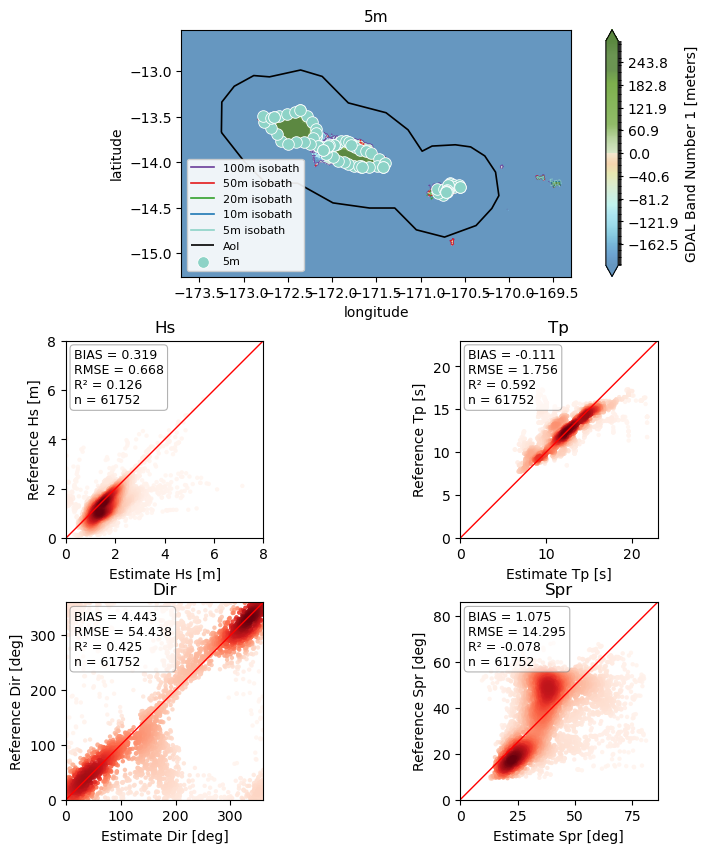

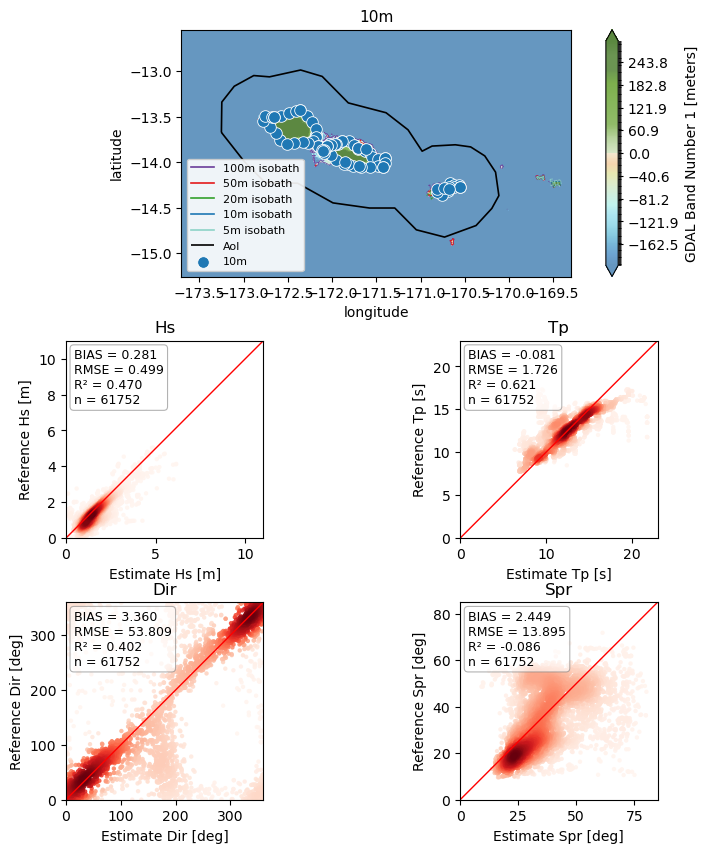

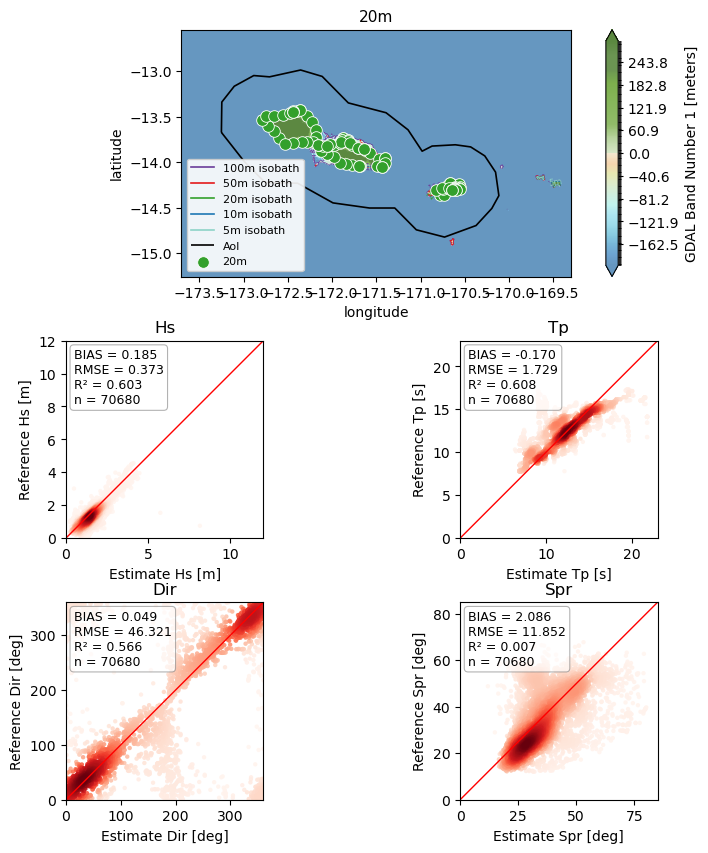

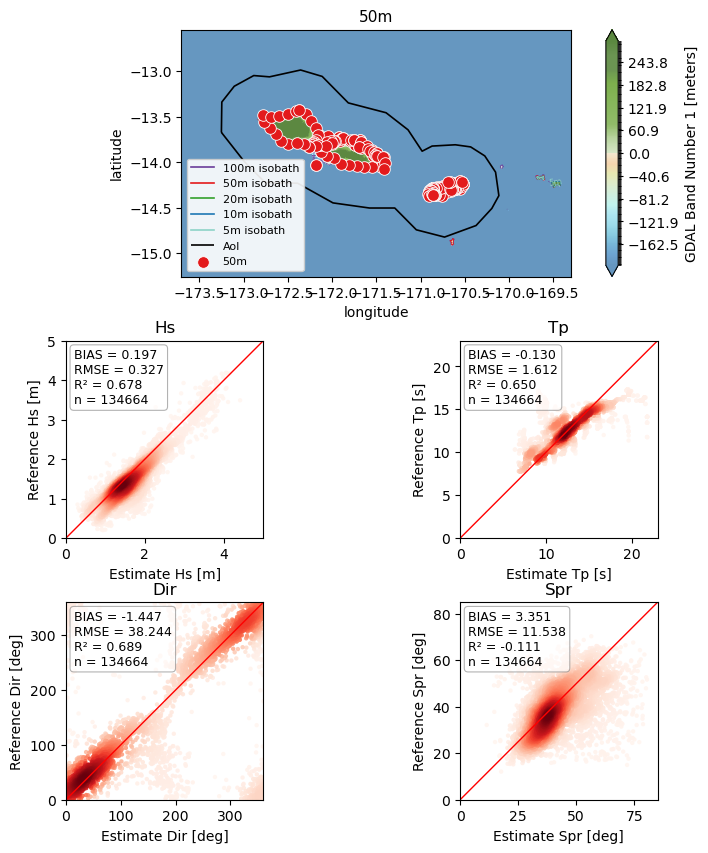

In [7]:
result.plot_all(variables=variables, cmap="Reds", groups=["5m", "10m", "20m", "50m"])
plt.show()

## 5 · Save metrics


In [8]:
metrics_out = result.metrics.copy()
metrics_out.insert(0, "period", period)
metrics_out.insert(1, "mda_candidate", mda_n)
metrics_out.insert(2, "offshore_name", offshore_name)
metrics_out["n_sites"] = int(metamodel.sizes["sites"])
# Wall time for mm.reconstruct() above — near-zero if these sites/period
# were already cached from a previous run, not a fresh-simulation cost.
metrics_out["reconstruct_seconds"] = reconstruct_seconds

out_path = val.metamodel_validation_path(period)
out_path.parent.mkdir(parents=True, exist_ok=True)
metrics_out.to_csv(out_path, index=False)
print(f"Wrote {out_path}")


Wrote /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/metamodel_validation/linear_summation_2020-01.csv
